# Лабораторная работа 7. Рекуррентная нейронная сеть и задача генерации текста

|  |  |
|---|---|
| Дисциплина | Машинное обучение |
| Студент | Масенькин Максим |
| Группа | ПИбд-41 |
| Вариант | 20 |

## Задание

Выбрать художественный текст (чётные варианты — русскоязычный, нечётные — англоязычный) и обучить
на нём рекуррентную нейронную сеть для решения задачи генерации. Подобрать архитектуру и параметры
так, чтобы приблизиться к максимально осмысленному результату. Далее разбиться на пары чётный —
нечётный вариант, обменяться разработанными сетями и проверить, как архитектура товарища
справляется с вашим текстом. В завершение подобрать компромиссную архитектуру, справляющуюся
достаточно хорошо с обоими видами текстов.

| Пункт задания | Вариант 20 |
|---|---|
| Язык текста | русский (20 — чётный вариант) |
| Текст | А. С. Пушкин, «Капитанская дочка» и «Повести Белкина», 303 тыс. символов |
| Текст напарника | те же произведения в английском переводе Т. Кина, 374 тыс.  |
| Модель | символьная рекуррентная сеть на Keras: `Embedding` — `LSTM` — `Dense` |
| Пособие | «Теория и практика машинного обучения»: рекуррентные сети и LSTM — стр. 131–132; LSTM в Keras — стр. 247–249, листинг 94; предсказание следующей буквы алфавита — стр. 274–275, листинг 98 |

## Ход работы

1. Подготовить тексты и символьный словарь.
2. Описать символьную модель и способ генерации.
3. Обучить свою сеть на русском тексте.
4. Подобрать архитектуру и температуру генерации.
5. Обменяться архитектурами с напарником.
6. Подобрать компромиссную архитектуру.

In [1]:
import os


os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"

from collections.abc import Collection, Sequence
import re
import time
from typing import TypedDict

import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf

from mllab import RANDOM_STATE
from mllab.gpu import load_cusolver
from mllab.reporting import make_table
from mllab.text import Vocabulary, generate, load_english, load_russian, make_windows, normalize


load_cusolver()
tf.config.experimental.enable_op_determinism()

LANGUAGES = {"ru": "русский", "en": "английский"}
VALIDATION = 0.1
STEP = 1
BATCH_SIZE = 256
MAX_EPOCHS = 40
PATIENCE = 3
SAMPLE_LENGTH = 300
SCORE_LENGTH = 2000
TEMPERATURES = [0.2, 0.3, 0.4, 0.5, 0.6, 0.8, 1.0, 1.2]
TEMPERATURE = 0.5
COLORS = {"ru": "#2a78d6", "en": "#eb6834"}

plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.titlesize": 10})
pd.set_option("display.width", 120)
pd.set_option("display.max_colwidth", None)

## 1. Тексты и словарь

В качестве текста для обучения выбрана проза Пушкина: «Капитанская дочка» (главы I–XIV) и пять
«Повестей Белкина». Тексты в общественном достоянии, язык близок к современному, предложения
короткие и простые — по такому тексту символьная сеть быстрее учится складывать слова. Тексты взяты
из Викитеки: «Капитанская дочка» — по собранию сочинений 1960 года, повести — по полному собранию
сочинений 1978 года, в современной орфографии.

Работа рассчитана на пару с нечётным вариантом, у которого текст английский. Напарника нет,
поэтому он эмулирован: для него взяты те же произведения в английском переводе Т. Кина 1916 года
из проекта Gutenberg, а его архитектура рассмотрена отдельно. Сюжет и стиль у текстов одни,
поэтому разницу в результатах на них можно объяснить только языком.

При загрузке тексты приведены к удобному виду:

- оставлен только авторский текст: без эпиграфов, стихов, сносок и заголовков глав; из сборника
  переводов убраны «Дубровский», «Пиковая дама» и остальные вещи, которых нет в русском тексте;
- все буквы переведены в нижний регистр, «ё» заменена на «е»;
- кавычки, многоточия и тире приведены к одному виду;
- убраны цифры, латиница в русском тексте (французские фразы) и надстрочные знаки в английском.

Произведения в обоих текстах идут в одном порядке. Последние 10% каждого текста отложены для
проверки, и в обоих случаях это конец «Барышни-крестьянки» с одного и того же места.

In [2]:
raw = {"ru": load_russian(), "en": load_english()}
texts = {language: normalize(text, language) for language, text in raw.items()}
vocabularies = {language: Vocabulary.from_text(text) for language, text in texts.items()}
codes = {language: vocabularies[language].encode(text) for language, text in texts.items()}
splits = {language: int(len(text) * (1 - VALIDATION)) for language, text in texts.items()}
known_words = {
    language: set(re.findall(r"\w+", text[: splits[language]])) for language, text in texts.items()
}


def corpus_summary(language: str) -> dict[str, int | float]:
    text, split = texts[language], splits[language]
    words = re.findall(r"\w+", text)
    validation_words = re.findall(r"\w+", text[split:])
    return {
        "символов в исходном тексте": len(raw[language]),
        "символов после очистки": len(text),
        "символов в словаре": len(vocabularies[language]),
        "слов": len(words),
        "разных слов": len(set(words)),
        "средняя длина слова": round(np.mean([len(word) for word in words]), 2),
        "символов в обучающей части": split,
        "символов в проверочной части": len(text) - split,
        "слов проверки, которых нет в обучении, %": round(
            100 * np.mean([word not in known_words[language] for word in validation_words]), 1
        ),
    }


pd.DataFrame(
    {
        LANGUAGES[language]: pd.Series(corpus_summary(language), dtype=object)
        for language in LANGUAGES
    }
)

,русский,английский
символов в исходном тексте,303355,374854
символов после очистки,303192,374464
символов в словаре,47,40
слов,47122,67501
разных слов,12194,6081
средняя длина слова,5.12,4.35
символов в обучающей части,272872,337017
символов в проверочной части,30320,37447
"слов проверки, которых нет в обучении, %",22.4,7.5


Перевод длиннее оригинала: 374 тыс. символов против 303 тыс. и 67.5 тыс. слов против 47.1 тыс. При
этом разных слов в русском тексте вдвое больше — 12.2 тыс. против 6.1 тыс. Русское слово меняет
окончание по падежам, числам и родам, и для сети «крепость», «крепости» и «крепостей» — три разных
слова. Поэтому 22.4% слов проверочной части русского текста не встречаются в обучающей. У
английского таких слов 7.5%. Сеть, которая видела слово только в одной форме, должна сама
подобрать к нему окончание, и русский текст для неё труднее.

Алфавиты различаются меньше: 47 символов против 40. Ниже словари и начало каждого текста после
очистки, `\n` — конец абзаца.

In [3]:
for language, name in LANGUAGES.items():
    print(f"{name}: {vocabularies[language].chars!r}")
    print(texts[language][:400], end="\n\n")

русский: '\n !"(),-.:;?«»абвгдежзийклмнопрстуфхцчшщъыьэюя—'
отец мой андрей петрович гринев в молодости своей служил при графе минихе и вышел в отставку премьер-майором в .. году. с тех пор жил он в своей симбирской деревне, где и женился на девице авдотье васильевне ю., дочери бедного тамошнего дворянина. нас было девять человек детей. все мои братья и сестры умерли во младенчестве.
матушка была еще мною брюхата, как уже я был записан в семеновский полк с

английский: '\n !"\'(),-.:;?abcdefghijklmnopqrstuvwxyz—'
my father, andrei petrovitch grineff, after having served in his youth under count munich, quitted the service, in the year —, with the rank of senior major. he settled down upon his estate in the district of simbirsk, where he married avdotia vassilevna u—, the daughter of a poor nobleman of the neighbourhood. nine children were the result of this marriage. all my brothers and sisters died in the



## 2. Символьная модель

Сеть учится по предыдущим $L$ символам угадывать следующий. Текст режется на окна: $L$ символов —
вход, символ сразу после окна — ответ. Окно сдвигается на $s$ символов, поэтому соседние окна
перекрываются. Например, при $L = 5$ и $s = 3$ из слова «капитанская» получаются две пары:

- «капит» → «а»;
- «итанс» → «к».

Ниже те же окна в виде кодов: каждый символ словаря получает номер по порядку.

In [4]:
vocabulary = vocabularies["ru"]
demo_inputs, demo_targets = make_windows(vocabulary.encode("капитанская"), 5, 3)
pd.DataFrame(
    {
        "вход": [vocabulary.decode(window) for window in demo_inputs],
        "коды": [window.tolist() for window in demo_inputs],
        "ответ": [vocabulary.decode([code]) for code in demo_targets],
    }
)

,вход,коды,ответ
0,капит,"[24, 14, 29, 22, 32]",а
1,итанс,"[22, 32, 14, 27, 31]",к


Сеть устроена как в листинге 98 пособия, где LSTM по одной букве алфавита предсказывает следующую,
но вход у неё — окно из $L$ символов, и перед LSTM стоит слой `Embedding`.

`Embedding` заменяет номер символа в словаре вектором из $d$ чисел. Эти числа обучаются вместе с
остальными весами, и символы, которые встречаются в похожем окружении, получают близкие векторы. В
листинге 98 номер буквы подаётся на вход как одно число $\text{номер} / 26$, и сеть вынуждена
считать «б» чем-то средним между «а» и «в». Вектор такой связи между соседними номерами не создаёт.

`LSTM` читает окно слева направо и после каждого символа обновляет два вектора: состояние $h_t$ и
память $c_t$:

$$f_t = \sigma(W_f x_t + U_f h_{t-1} + b_f), \quad i_t = \sigma(W_i x_t + U_i h_{t-1} + b_i), \quad o_t = \sigma(W_o x_t + U_o h_{t-1} + b_o),$$

$$c_t = f_t \odot c_{t-1} + i_t \odot \tanh(W_c x_t + U_c h_{t-1} + b_c), \qquad h_t = o_t \odot \tanh(c_t),$$

где $x_t$ — вектор $t$-го символа, $\sigma$ — сигмоида со значениями от 0 до 1, $\odot$ —
поэлементное умножение. Сигмоиды работают как заслонки: $f_t$ решает, какую часть памяти забыть,
$i_t$ — что в неё записать, $o_t$ — что из неё выдать наружу. Число нейронов слоя — длина векторов
$h_t$ и $c_t$.

В простой рекуррентной сети состояние на каждом шаге заново умножается на матрицу весов, и то, что
было в начале окна, через сотню шагов почти стирается. В LSTM память меняется сложением, и
открытая кавычка или начало реплики в начале окна могут дожить до его конца.

`Dense` с функцией softmax переводит последнее состояние $h_L$ в вероятности всех символов словаря.
Слоёв `LSTM` может быть несколько, тогда следующий слой читает последовательность состояний
предыдущего.

### Функция потерь

Сеть обучается минимизировать перекрёстную энтропию — минус среднее логарифмов вероятностей,
которые сеть дала правильным символам:

$$\mathcal{L} = -\frac{1}{N} \sum_{n=1}^{N} \ln p_n(y_n).$$

Если правильному символу дана вероятность 0.5, слагаемое равно 0.69, если 0.1 — уже 2.30. Сеть,
которая выбирает символ наугад из 47, получает $\ln 47 = 3.85$. Удобно смотреть и на
$e^{\mathcal{L}}$: при $\mathcal{L} = 2$ сеть в среднем сомневается так, будто выбирает из
$e^2 \approx 7.4$ равновероятных символов.

Последние 10% каждого текста в обучении не участвуют. Ошибка на них показывает, как сеть
предсказывает текст, которого не видела. Обучение останавливается, когда эта ошибка 3 эпохи подряд
не уменьшается, и сеть возвращается к весам лучшей эпохи.

### Генерация и температура

Текст генерируется по одному символу: сеть получает последние $L$ символов, выдаёт вероятности,
из них случайно выбирается следующий символ, он дописывается к тексту, и окно сдвигается. Перед
выбором вероятности пересчитываются с температурой $T$:

$$p_i^{(T)} = \frac{p_i^{1/T}}{\sum_j p_j^{1/T}}.$$

Пусть сеть дала трём символам вероятности 0.6, 0.3 и 0.1:

- при $T = 0.5$ они становятся 0.78, 0.20 и 0.02;
- при $T = 2$ — 0.47, 0.33 и 0.19.

Низкая температура почти всегда выбирает самый вероятный символ, и текст получается грамотным, но
однообразным, вплоть до повторения одной фразы. Высокая выравнивает вероятности, текст становится
разнообразнее, но в нём больше несуществующих слов.

Осмысленность текста одной формулой не измерить. Кроме ошибки на проверке, считается доля
настоящих слов: сгенерированный текст делится на слова, и считается, какая их доля встречается в
обучающей части текста. Повтор одной фразы эта доля не наказывает, поэтому примеры генерации
приводятся рядом с ней.

Ниже функции, общие для всех сетей работы: сборка сети, обучение до остановки по ошибке на
проверке, генерация и подсчёт настоящих слов. Генерация начинается с последних $L$ символов
обучающей части перед началом абзаца, так что сеть продолжает текст с нового абзаца.

In [5]:
class Architecture(TypedDict):
    window: int
    embedding: int
    units: int
    layers: int
    dropout: float


class Run(TypedDict):
    language: str
    model: keras.Model
    history: pd.DataFrame
    minutes: float


def build_model(
    vocabulary_size: int, *, window: int, embedding: int, units: int, layers: int, dropout: float
) -> keras.Sequential:
    model = keras.Sequential([keras.Input((window,), dtype="int32")])

    if embedding:
        model.add(keras.layers.Embedding(vocabulary_size, embedding))
    else:
        model.add(keras.layers.CategoryEncoding(vocabulary_size, output_mode="one_hot"))

    for layer in range(layers):
        model.add(keras.layers.LSTM(units, return_sequences=layer < layers - 1))
        if dropout:
            model.add(keras.layers.Dropout(dropout))

    model.add(keras.layers.Dense(vocabulary_size, activation="softmax"))
    model.compile(loss="sparse_categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
    return model


def seed_text(language: str, window: int) -> str:
    text, split = texts[language], splits[language]
    end = text.rindex("\n", 0, split) + 1
    return text[end - window : end]


def sample_text(
    language: str, model: keras.Model, temperature: float, length: int = SAMPLE_LENGTH
) -> str:
    seed = seed_text(language, model.input_shape[1])
    rng = np.random.default_rng(RANDOM_STATE)
    return generate(model, vocabularies[language], seed, length, temperature=temperature, rng=rng)


def real_words(language: str, text: str) -> float:
    words = re.findall(r"\w+", text)[:-1]
    return np.mean([word in known_words[language] for word in words])


def epoch_samples(
    language: str, epochs: Collection[int], samples: dict[int, str]
) -> keras.callbacks.LambdaCallback:
    def on_epoch_end(epoch: int, _logs: dict[str, float]) -> None:
        if epoch + 1 in epochs:
            samples[epoch + 1] = sample_text(language, callback.model, TEMPERATURE)

    callback = keras.callbacks.LambdaCallback(on_epoch_end=on_epoch_end)
    return callback


def train(
    language: str, architecture: Architecture, callbacks: Sequence[keras.callbacks.Callback] = ()
) -> Run:
    keras.utils.set_random_seed(RANDOM_STATE)
    window, data, split = architecture["window"], codes[language], splits[language]
    X_train, y_train = make_windows(data[:split], window, STEP)
    validation = make_windows(data[split - window :], window, STEP)
    model = build_model(len(vocabularies[language]), **architecture)
    stop = keras.callbacks.EarlyStopping(patience=PATIENCE, restore_best_weights=True)
    started = time.perf_counter()
    history = model.fit(
        X_train,
        y_train,
        batch_size=BATCH_SIZE,
        epochs=MAX_EPOCHS,
        validation_data=validation,
        callbacks=[stop, *callbacks],
        verbose=0,
    )
    history = pd.DataFrame(history.history, index=range(1, len(history.epoch) + 1))
    return {
        "language": language,
        "model": model,
        "history": history,
        "minutes": (time.perf_counter() - started) / 60,
    }


def summary(run: Run, temperature: float) -> dict[str, int | float]:
    history = run["history"]
    best = history["val_loss"].idxmin()
    return {
        "весов": run["model"].count_params(),
        "эпох": len(history),
        "лучшая эпоха": best,
        "ошибка на обучении": round(history.loc[best, "loss"], 3),
        "ошибка на проверке": round(history.loc[best, "val_loss"], 3),
        "точность на проверке": round(history.loc[best, "val_accuracy"], 3),
        f"настоящих слов при T = {temperature}": round(
            real_words(
                run["language"],
                sample_text(run["language"], run["model"], temperature, SCORE_LENGTH),
            ),
            3,
        ),
        "минут обучения": round(run["minutes"], 1),
    }

## 3. Своя сеть на русском тексте

Первая сеть — самая простая: окно из 100 символов, `Embedding` на 32 числа, один слой `LSTM` из 256
нейронов, без dropout. В 100 символов помещается около 17 слов, т. е. одно-два предложения.

Окна нарезаны с шагом 1, и каждый символ обучающей части один раз становится ответом. Если брать
окна через 3 символа, две трети символов ответом не станут ни разу. В пробном запуске с шагом 3 та
же сеть дала на проверке ошибку 1.98 против 1.78.

Веса подбираются так же, как у сети в ЛР 6: по шагам против градиента, а градиент считается
обратным распространением ошибки, у рекуррентной сети — через все 100 шагов окна. В ЛР 6 шаг
выбирал `lbfgs`, который считает градиент сразу по всей выборке. Здесь обучающих окон 273 тыс., и
выбран оптимизатор Adam: он делает шаг по каждой пачке из 256 окон и подстраивает шаг для каждого
веса по истории его градиентов. Одна эпоха — один проход по всем окнам обучающей части. Обучение
идёт на видеокарте.

Начальные веса и порядок пачек случайные, поэтому seed зафиксирован константой проекта, а на
видеокарте включены детерминированные операции, чтобы результаты повторялись между запусками.

In [6]:
FIRST = {"window": 100, "embedding": 32, "units": 256, "layers": 1, "dropout": 0.0}
SAMPLE_EPOCHS = [1, 2, 4, 8]

samples_by_epoch = {}
first = train("ru", FIRST, callbacks=[epoch_samples("ru", SAMPLE_EPOCHS, samples_by_epoch)])
make_table(
    {
        "видеокарта": ", ".join(
            tf.config.experimental.get_device_details(device)["device_name"]
            for device in tf.config.list_physical_devices("GPU")
        ),
        **summary(first, TEMPERATURE),
    }
)

,значение
,
видеокарта,NVIDIA GeForce RTX 4080
весов,309519
эпох,13
лучшая эпоха,10
ошибка на обучении,1.463
ошибка на проверке,1.779
точность на проверке,0.474
настоящих слов при T = 0.5,0.87
минут обучения,2.9


Обучение остановилось на 13-й эпохе: после 10-й ошибка на проверке три эпохи подряд не уменьшалась,
и сеть вернулась к весам 10-й эпохи. На проверке ошибка 1.779, т. е. сеть сомневается так, будто
выбирает из $e^{1.779} \approx 5.9$ равновероятных символов, и угадывает следующий символ в 47%
случаев. В тексте, сгенерированном при $T = 0.5$, 87% слов встречаются в обучающей части. Ниже
ошибка по эпохам.

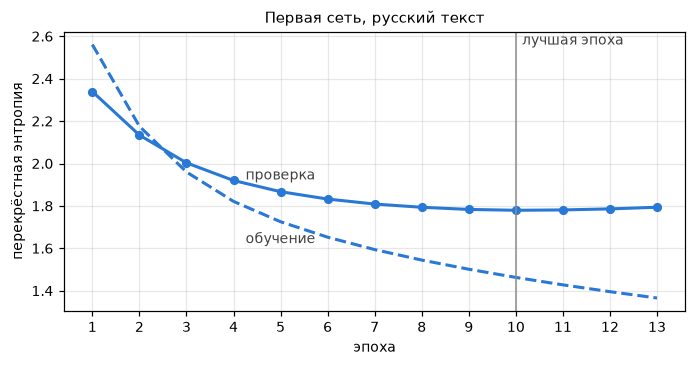

In [7]:
history = first["history"]
best = history["val_loss"].idxmin()
color = COLORS["ru"]

fig, ax = plt.subplots(figsize=(6.4, 3.4))
ax.plot(history.index, history["loss"], color=color, linewidth=2, linestyle="--")
ax.plot(history.index, history["val_loss"], color=color, linewidth=2, marker="o", markersize=5)
ax.axvline(best, color="0.55", linewidth=1)
for column, label, offset in [("loss", "обучение", -14), ("val_loss", "проверка", 8)]:
    ax.annotate(
        label,
        (5, history.loc[5, column]),
        xytext=(0, offset),
        textcoords="offset points",
        ha="center",
        color="0.25",
    )
ax.annotate(
    "лучшая эпоха",
    (best, history["loss"].max()),
    xytext=(4, 0),
    textcoords="offset points",
    color="0.25",
)
ax.set_xticks(history.index)
ax.set_xlabel("эпоха")
ax.set_ylabel("перекрёстная энтропия")
ax.set_title("Первая сеть, русский текст")
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

Ошибка на обучении падает все 13 эпох, на проверке — только до 10-й. С 3-й эпохи ошибка на
обучении ниже, чем на проверке, и разрыв растёт: сеть всё лучше помнит обучающий текст, а новый
предсказывает не лучше. Это переобучение, и остановка по ошибке на проверке его обрезает.

Ниже текст, который сеть генерирует после 1, 2, 4 и 8 эпох и с лучшими весами, при $T = 0.5$.

In [8]:
for epoch, text in samples_by_epoch.items():
    print(f"--- эпоха {epoch} ---\n{text}\n")
print(f"--- эпоха {best}, лучшие веса ---\n{sample_text('ru', first['model'], TEMPERATURE)}")

--- эпоха 1 ---
— стачел одресте вородуть на продисте и ото стоен и соможил поромил ваздил меротнит, же договел на тризсти и слазались она на медлени, было несто менано обрасти с болом томествия просморили с воледо, сто боло не коров сказатись обель стора, что совенится от воере сазал в ене меря и не вне с самоть о

--- эпоха 2 ---
— сказал он приводно морого долько его посторовать было не вседного волом голодом по воредение остарывать. масте на соверил. он влаздел сем опримение спереником свамерними. я вошил селовее из из мне несто кименные приводились, привители оберовной ледетрие поводовать за взами и стал коменданит просто

--- эпоха 4 ---
— сказал он, — отвечал я говоритель и не стану. по всем меня отвечал он с верим порвадика, подамел столь поварили его не под погазанном сомендино, когда не мого следами. не тебя разнилось последились пугачеву мое совершенных с ним отвечать савельича, что со всем довал в меня и стал меня однакомурник

--- эпоха 8 ---
— со столь становился с поледн

--- эпоха 10, лучшие веса ---
— прощай, не смотря на стариком. не волосод только бы со мною простился по объяснение остановился в то совести. он простился на доброе было неговоличась меня предположение. я встретил на крепости не мог на красного по себя с увидения присметление. он подал его свою колене. он проводил девушку не ста


После первой эпохи сеть уже разделяет слова пробелами и составляет похожие на слова сочетания букв.
Настоящие слова среди них только короткие («на», «и», «было»). После второй эпохи появляются частые
обороты из текста. К 4-й эпохе сеть ставит тире в репликах и вспоминает имена героев. С лучшими
весами почти все слова настоящие, но согласование держится на два-три слова.

## 4. Подбор архитектуры и температуры

Число слоёв и нейронов, dropout и длина окна не обучаются вместе с весами, их задают до обучения.
В ЛР 6 такие параметры подбирались перебором всех комбинаций с кросс-валидацией. Здесь одна сеть
обучается от 2 до 8 минут, поэтому от первой сети меняется по одному параметру, а сети сравниваются
по ошибке на проверочной части текста.

Dropout — тоже регуляризация, как коэффициент $\alpha$ в ЛР 6, но веса он не штрафует: при обучении
слой на каждой пачке окон обнуляет случайную долю $p$ выходов LSTM, каждый раз других, а при
генерации не обнуляет ничего. Пусть у слоя 10 выходов и $p = 0.4$: на каждой пачке сеть видит
только 6 случайных из них и не может опереться на один нейрон, который запомнил конкретную фразу.
Ошибка на обучении из-за этого растёт, а на проверке — падает, если сеть до этого переобучалась.

У сети из двух слоёв по 512 нейронов 3.24 млн весов на 273 тыс. обучающих окон. Весов больше, чем
примеров, как у сети в ЛР 6, и без регуляризации ей проще запомнить текст, чем научиться его
продолжать.

In [9]:
TUNING = {
    "1 × 256": FIRST,
    "1 × 512": {**FIRST, "units": 512},
    "2 × 512, dropout 0.2": {**FIRST, "units": 512, "layers": 2, "dropout": 0.2},
    "2 × 512, dropout 0.4": {**FIRST, "units": 512, "layers": 2, "dropout": 0.4},
    "2 × 512, dropout 0.4, окно 60": {
        **FIRST,
        "window": 60,
        "units": 512,
        "layers": 2,
        "dropout": 0.4,
    },
}

tuned = {
    name: first if architecture is FIRST else train("ru", architecture)
    for name, architecture in TUNING.items()
}
pd.DataFrame.from_dict(
    {name: summary(run, TEMPERATURE) for name, run in tuned.items()}, orient="index"
)

,весов,эпох,лучшая эпоха,ошибка на обучении,ошибка на проверке,точность на проверке,настоящих слов при T = 0.5,минут обучения
1 × 256,309519,13,10,1.463,1.779,0.474,0.870,2.9
1 × 512,1141775,8,5,1.392,1.757,0.479,0.841,2.2
"2 × 512, dropout 0.2",3240975,9,6,1.381,1.673,0.498,0.901,4.7
"2 × 512, dropout 0.4",3240975,14,11,1.333,1.646,0.511,0.914,7.3
"2 × 512, dropout 0.4, окно 60",3240975,11,8,1.440,1.651,0.505,0.918,4.0


Если в одном слое 512 нейронов вместо 256, ошибка почти не меняется: 1.757 против 1.779. Весов при
этом в 3.7 раза больше, и сеть переобучается раньше — лучшая эпоха 5-я против 10-й.

Второй слой с dropout 0.2 снижает ошибку до 1.673, dropout 0.4 — до 1.646. С dropout 0.4 сеть
дольше не переобучается: лучшая эпоха 11-я против 6-й при 0.2. Ошибка на обучении у неё даже ниже,
1.333 против 1.381, т. к. сеть обучалась почти вдвое дольше.

Окно 60 символов вместо 100 даёт ошибку 1.651 против 1.646, почти то же, а обучение быстрее: 4.0
минуты против 7.3. В 60 символов помещается около 10 слов, и для выбора следующей буквы этого почти
всегда хватает.

Наименьшая ошибка у сети с двумя слоями по 512 нейронов, dropout 0.4 и окном 100. Архитектура
выбрана по той же проверочной части, по которой останавливается обучение: отдельной части для
подбора, как отложенной выборки в ЛР 6, здесь нет, чтобы не отнимать текст у обучения. Поэтому
ошибка выбранной сети может быть немного занижена — так же, как в ЛР 6 могла быть завышена оценка
сети на кросс-валидации.

Ниже доля настоящих слов в её тексте в зависимости от температуры.

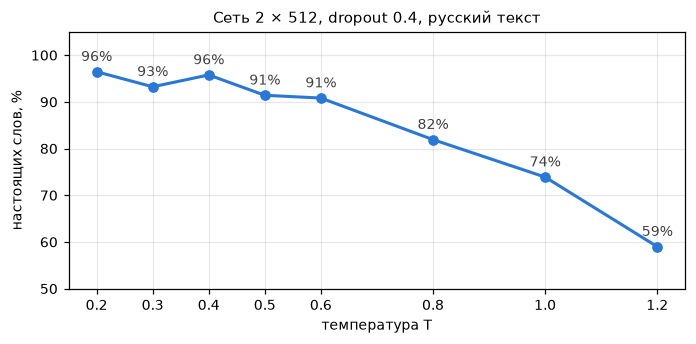

In [10]:
best_name = min(tuned, key=lambda name: tuned[name]["history"]["val_loss"].min())
mine = tuned[best_name]
by_temperature = {
    temperature: sample_text("ru", mine["model"], temperature, SCORE_LENGTH)
    for temperature in TEMPERATURES
}
shares = pd.Series(
    {temperature: real_words("ru", text) for temperature, text in by_temperature.items()}
)

fig, ax = plt.subplots(figsize=(6.4, 3.2))
ax.plot(shares.index, shares * 100, color=COLORS["ru"], linewidth=2, marker="o", markersize=6)
for temperature, share in shares.items():
    ax.annotate(
        f"{share:.0%}",
        (temperature, share * 100),
        xytext=(0, 7),
        textcoords="offset points",
        ha="center",
        color="0.25",
    )
ax.set_xticks(TEMPERATURES)
ax.set_ylim(50, 105)
ax.set_yticks(range(50, 101, 10))
ax.set_xlabel("температура T")
ax.set_ylabel("настоящих слов, %")
ax.set_title(f"Сеть {best_name}, русский текст")
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

При $T$ от 0.2 до 0.6 настоящих слов 91–96%, дальше доля быстро падает: при $T = 1.2$ — 59%.
Небольшие скачки между соседними температурами — случайность: доля считается по одному тексту из
2000 символов. Ниже примеры при четырёх температурах.

In [11]:
for temperature in [0.2, 0.5, 0.8, 1.2]:
    text = by_temperature[temperature]
    print(f"--- T = {temperature} ---\n{text[:SAMPLE_LENGTH]}\n")

--- T = 0.2 ---
я стал под своей положение.
марья ивановна простилась к нам по простой и подозрения, и в котором после он подошел к нему на коменданту в самом деле, в самом деле, в котором подошел к нему на него на нему в невольное волнение. в самом деле должно было не проводить с меня по своем моем под караулом. о

--- T = 0.5 ---
я старался с положении. по дорогу и возвращались в бороду и поминутно должно было ожеда.
я получил собою под своем солдатом.
однако ж обыкновенно приближался к ее волнение. я вошел в нем и кривой моей успехах и посторонный службе и тотчас отдаленный одним разговоре и в вами подставить в обыкновенной

--- T = 0.8 ---
это было минута надежды. девушки мое его старила глаза. не было не играть в крепости верно привести себя по всем порядком.
марья ивановна с нею не могла нанеможет были зимертва что-то ризать. все не заснула меня ваше бурецу. я отвечал. мне старика не смело, видя все бог в полку с делом и всем строги

--- T = 1.2 ---
через предложил матушку-те бел

При $T = 0.2$ сеть почти всегда выбирает самый вероятный символ и зацикливается: «в самом деле»
повторяется трижды, «подошел к нему» — дважды. При $T = 0.8$ и выше слова чаще ломаются:
«нанеможет», «зимертва», «колендерци». При $T = 0.5$ текст разнообразный, а несуществующих слов в
нём мало, поэтому дальше все сети сравниваются при этой температуре. Смысла в тексте нет ни при
какой температуре: она меняет только то, повторяет ли сеть частые обороты или ломает слова.

## 5. Архитектура напарника

Архитектура напарника задана так, чтобы отличаться от моей везде, где был выбор:

- символы подаются на вход в виде one-hot, т. е. вектора длины словаря с единицей на месте символа,
  без обучаемого `Embedding`. Соседние номера, как и в `Embedding`, ничем не связаны, но и похожие
  символы не сближаются: все векторы одинаково далеки друг от друга;
- два слоя `LSTM` по 256 нейронов вместо двух по 512;
- окно 60 символов вместо 100: для английского текста это около 11 слов;
- без dropout.

Обе архитектуры обучены на обоих текстах.

In [12]:
MINE = TUNING[best_name]
PARTNER = {"window": 60, "embedding": 0, "units": 256, "layers": 2, "dropout": 0.0}
ARCHITECTURES = {"моя": MINE, "напарника": PARTNER}

cross = {("моя", "ru"): mine}
for name, architecture in ARCHITECTURES.items():
    for language in LANGUAGES:
        if (name, language) not in cross:
            cross[name, language] = train(language, architecture)

pd.DataFrame.from_dict(
    {
        (f"сеть {name}", LANGUAGES[language]): summary(run, TEMPERATURE)
        for (name, language), run in cross.items()
    },
    orient="index",
).sort_index()

весов  эпох  лучшая эпоха  ошибка на обучении  ошибка на проверке  точность на проверке  \
сеть моя       английский  3237160    13            10               1.102               1.346                 0.601   
               русский     3240975    14            11               1.333               1.646                 0.511   
сеть напарника английский   839720     8             5               1.234               1.472                 0.564   
               русский      848687     9             6               1.469               1.788                 0.468   

                           настоящих слов при T = 0.5  минут обучения  
сеть моя       английский                       0.982             8.5  
               русский                          0.914             7.3  
сеть напарника английский                       0.937             2.3  
               русский                          0.764             2.1

Моя архитектура лучше на обоих текстах: на русском ошибка 1.646 против 1.788, на английском — 1.346
против 1.472. Разница почти одинаковая, 0.14 и 0.13. Сеть напарника на русском тексте не лучше моей
первой сети (1.779): у неё нет dropout, и она переобучается уже к 6-й эпохе. Зато она обучается в
3.5–3.7 раза быстрее: весов у неё почти вчетверо меньше, окно короче, и останавливается она раньше.

Ошибку на разных языках напрямую сравнивать нельзя: у английского меньше алфавит, слова в нём чаще
повторяются, а сам текст длиннее. Следующий символ в нём предсказать проще, и у обеих сетей ошибка
на английском ниже на 0.3. Долю настоящих слов сравнивать можно. У моей сети она 98% на английском
и 91% на русском, у сети напарника — 94% и 76%. На русском тексте сеть напарника теряет 18 пунктов,
моя — 7. Скорее всего, дело в словоформах: у русского текста их вдвое больше, и сети без
регуляризации труднее научиться окончаниям, чем запомнить слова целиком.

Ниже примеры текста всех четырёх сетей при $T = 0.5$.

In [13]:
for (name, language), run in sorted(cross.items()):
    text = sample_text(language, run["model"], TEMPERATURE)
    print(f"--- сеть {name}, {LANGUAGES[language]} текст ---\n{text}\n")

--- сеть моя, английский текст ---
"what do you want to grow hang the confused postmaster. on are story to the contrary moment, and having the confused part of the postmaster, and i had seen the conclusion of savelitch with all the sensible and some tears of the paper room and set out to disperse in the commandant's house. the street



--- сеть моя, русский текст ---
я старался с положении. по дорогу и возвращались в бороду и поминутно должно было ожеда.
я получил собою под своем солдатом.
однако ж обыкновенно приближался к ее волнение. я вошел в нем и кривой моей успехах и посторонный службе и тотчас отдаленный одним разговоре и в вами подставить в обыкновенной



--- сеть напарника, английский текст ---
"what do you think that the cours, and the great call of the great days of a sight of the commandant. it was the postmaster and dounia attending the bride, and his hand the table, or a share and enterested to the room of the same country, and the old man was not an indeble of the commandant's wife. 



--- сеть напарника, русский текст ---
— не унность подумала, что батюшка не заметил, когда противая сильно его два моим под разими и остановился и с марье ивановие и доброго соседи, и не встал и стал и сказал он, в четоре не было все представать и повесила, и присматрие мое с моим положении и с котором на велел из следующего доброй стол



Английский текст обеих сетей читается почти как английские фразы: «the old man was not», «the
commandant's house». В русском тексте сети напарника несуществующих слов заметно больше:
«унность», «противая», «марье ивановие», «четоре».

## 6. Компромиссная архитектура

Компромиссная архитектура должна на каждом тексте работать почти так же, как лучшая для него сеть.
Моя сеть лучше на обоих текстах, так что выбирать приходится между качеством и временем обучения.

Из обеих архитектур взято то, что подошло обоим текстам. От моей — `Embedding`, два слоя по 512
нейронов и dropout 0.4: без них сеть напарника заметно хуже на русском тексте. От сети напарника —
окно 60 символов: в разделе 4 оно почти не ухудшило ошибку на русском тексте и ускорило обучение.
На русском тексте такая сеть уже обучена в разделе 4, на английском она обучается ниже. В таблице
отставание — разница между ошибкой сети и наименьшей ошибкой на этом тексте.

In [14]:
COMPROMISE = TUNING["2 × 512, dropout 0.4, окно 60"]
compromise = {"ru": tuned["2 × 512, dropout 0.4, окно 60"], "en": train("en", COMPROMISE)}
candidates = {
    "моя": {language: cross["моя", language] for language in LANGUAGES},
    "напарника": {language: cross["напарника", language] for language in LANGUAGES},
    "компромиссная": compromise,
}
best_loss = {
    language: min(runs[language]["history"]["val_loss"].min() for runs in candidates.values())
    for language in LANGUAGES
}


def comparison(runs: dict[str, Run]) -> dict[tuple[str, str], float]:
    row = {}
    for language, run in runs.items():
        loss = run["history"]["val_loss"].min()
        row[LANGUAGES[language], "ошибка на проверке"] = round(loss, 3)
        row[LANGUAGES[language], "отставание от лучшей"] = round(loss - best_loss[language], 3)
        row[LANGUAGES[language], "минут обучения"] = round(run["minutes"], 1)
    return row


pd.DataFrame({f"сеть {name}": comparison(runs) for name, runs in candidates.items()}).T

русский                                             английский                       \
                   ошибка на проверке отставание от лучшей минут обучения ошибка на проверке отставание от лучшей   
сеть моя                        1.646                0.000            7.3              1.346                0.000   
сеть напарника                  1.788                0.142            2.1              1.472                0.126   
сеть компромиссная              1.651                0.005            4.0              1.361                0.015   

                                   
                   минут обучения  
сеть моя                      8.5  
сеть напарника                2.3  
сеть компромиссная            5.4

Компромиссная сеть отстаёт от моей на 0.005 на русском тексте и на 0.015 на английском. Это меньше,
чем разница между dropout 0.2 и 0.4 в разделе 4. Обучается она быстрее: 4.0 минуты против 7.3 на
русском тексте и 5.4 против 8.5 на английском. Сеть напарника обучается ещё быстрее, но отстаёт на
0.13–0.14.

Ниже текст компромиссной сети на обоих языках.

In [15]:
for language, run in compromise.items():
    text = sample_text(language, run["model"], TEMPERATURE)
    print(f"--- {LANGUAGES[language]} текст ---\n{text}\n")

--- русский текст ---
— слава богу, что ты мой батюшка, — отвечал я с первый сердце. — он был с вами старалась к отцу и вышла и подозвал поворона, и в последними последними своего советами. но она была старого службы и с крыльца размышления, которые на моего салую после обыкновенного возвратели; но я видел в объяснения. 



--- английский текст ---
"the words were not to the count and savelitch did not see how the day in a great man to see him a word, and when he was not seemed to drink any defensive persons and the postmaster, and he was a strange accused of the hands of the window and set out to his arms and commandant to him, and the street



По тексту компромиссная сеть не отличается от моей: слова почти все настоящие, реплики оформлены
тире и кавычками, но согласование держится на нескольких словах подряд.

### Оценка метода

Для генерации текста символьная LSTM подходит частично. На 300 тыс. символов она выучила
орфографию, частые обороты, имена героев и оформление прямой речи. При $T = 0.5$ девять слов из
десяти в русском тексте настоящие, в английском — почти все. Связного смысла в тексте нет: сеть
выбирает следующий символ по последним нескольким словам, а сюжет и даже конец предложения не
планирует. Чтобы приблизиться к осмысленному тексту, нужен текст на порядки больше или модель,
которая работает со словами и частями слов.

## Выводы

1. Для генерации выбрана проза Пушкина: «Капитанская дочка» и «Повести Белкина», 303 тыс. символов.
   Напарник с нечётным вариантом эмулирован, его текст — английский перевод тех же произведений.
2. Русский текст для символьной сети труднее английского: разных словоформ в нём вдвое больше, и
   22.4% слов проверочной части не встречаются в обучающей против 7.5% у английского.
3. Простая сеть из одного слоя LSTM на 256 нейронов переобучается после 10 эпох, ошибка на
   проверке 1.779. Ошибку снизили второй слой и dropout 0.4: до 1.646, при $T = 0.5$ настоящих слов
   91%. Число нейронов в одном слое и длина окна от 60 до 100 символов почти не влияют. Температура
   0.5 — компромисс между зацикливанием при низкой температуре и сломанными словами при высокой.
4. Моя архитектура лучше архитектуры напарника на обоих текстах на 0.13–0.14. Сеть напарника без
   `Embedding` и dropout на русском тексте теряет больше: настоящих слов 76% против 94% на
   английском.
5. Компромиссная архитектура — моя сеть с окном 60 символов из архитектуры напарника. Она отстаёт
   от лучшей на 0.005 на русском тексте и на 0.015 на английском и обучается в 1.6–1.8 раза
   быстрее.
6. Сети пишут грамотные слова и короткие обороты, но связного смысла в тексте нет: на тексте такого
   объёма символьная сеть учит орфографию и частые сочетания слов, до содержания дело не доходит.

## Контрольные вопросы

**1. Какой текст вы выбрали и почему?**

Прозу Пушкина: «Капитанскую дочку» и пять «Повестей Белкина», 303 тыс. символов после очистки.
Вариант чётный, поэтому текст русский. Тексты в общественном достоянии, есть в Викитеке в
современной орфографии, язык близок к современному, а предложения короткие. Объём такой, что сеть
обучается на видеокарте за несколько минут. У этих произведений есть английский перевод, поэтому
текст эмулированного напарника отличается от моего только языком.

**2. Какова архитектура вашей сети?**

Символьная рекуррентная сеть: `Embedding` переводит каждый из 47 символов словаря в вектор из 32
чисел, затем два слоя `LSTM` по 512 нейронов, после каждого dropout 0.4, и `Dense` с softmax на 47
выходов. Вход — окно из 100 предыдущих символов, выход — вероятности следующего символа, всего 3.24
млн весов. Сеть обучается минимизировать перекрёстную энтропию оптимизатором Adam пачками по 256
окон. Текст генерируется по символу, следующий символ выбирается случайно по вероятностям,
пересчитанным с температурой 0.5. Компромиссная архитектура та же, но с окном 60 символов.

**3. На скольких эпохах вы её обучали и каких результатов удалось добиться?**

Обучение останавливается, когда ошибка на отложенных 10% текста 3 эпохи подряд не уменьшается, и
сеть возвращается к весам лучшей эпохи. Моя сеть обучалась 14 эпох, лучшая — 11-я, на видеокарте
это 7.3 минуты. Ошибка на проверке 1.646, следующий символ сеть угадывает в 51% случаев. В тексте,
сгенерированном при $T = 0.5$, 91% слов настоящие, слова согласуются на два-три слова подряд, а
связного смысла нет. На английском тексте та же архитектура дала ошибку 1.346 и 98% настоящих слов.